# MobileNetV3-Small — Waste Classification (Checkpoint 1)

Paper: Yong, L., Ma, L., Sun, D., & Du, L. (2023). *Application of MobileNetV2 to waste classification.*
PLOS ONE 18(3): e0282336. <https://doi.org/10.1371/journal.pone.0282336>

Notebook ini menjalankan **MobileNetV3-Small** pada dataset, split, dan protokol training yang sama
dengan eksperimen MobileNetV2 dan CNN. Semua artefak ditulis ke `outputs/` di root repository.

## Daftar isi

1. Setup dan konfigurasi
2. Dataset dan split
3. Transform dan loader
4. Model MobileNetV3-Small
5. Training loop
6. Tiga varian training
7. Kurva training
8. Evaluasi test
9. Confusion matrix
10. Analisis error
11. Perbandingan dengan baseline
12. Simpan ringkasan

## 1. Setup dan konfigurasi

Hyperparameter dasar mengikuti `train_245_class.py` (SGD 0,001, momentum 0,9, StepLR 7/0,1,
50 epoch, batch 42) agar hasil MobileNetV3-Small sebanding dengan MobileNetV2 dan CNN.

Tiga varian training dijalankan berurutan di notebook ini. Ketiganya memakai arsitektur, split,
seed, transform evaluasi, jumlah epoch, dan early stopping yang sama; hanya resep training yang
berbeda. Semua varian diekspor dengan prefix masing-masing.

In [1]:
# ---------------------------------------------------------------------------
# Auto-install dependencies. Packages that are already installed are untouched.
# ---------------------------------------------------------------------------
from __future__ import annotations

import importlib.util
import subprocess
import sys


def module_available(name: str) -> bool:
    return importlib.util.find_spec(name) is not None


def pip_install(*packages: str, index_url: str | None = None) -> bool:
    command = [sys.executable, "-m", "pip", "install", "-q"]
    if index_url:
        command += ["--index-url", index_url]
    command += list(packages)
    print("    $", " ".join(command))
    try:
        return subprocess.run(command, check=False).returncode == 0
    except Exception as exc:
        print(f"[warn] pip install failed for {' '.join(packages)}: {exc}")
        return False


def ensure(packages: dict[str, str]) -> list[str]:
    missing = [pkg for pkg, mod in packages.items() if not module_available(mod)]
    if not missing:
        return []
    print(f"[setup] installing: {', '.join(missing)}")
    for package in missing:
        pip_install(package)
    still_missing = [pkg for pkg in missing if not module_available(packages[pkg])]
    if still_missing:
        print("[warn] could not install: " + ", ".join(still_missing))
    return still_missing


ensure({
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "scikit-learn": "sklearn",
    "Pillow": "PIL",
    "tqdm": "tqdm",
    "ipywidgets": "ipywidgets",
})

if not module_available("torch") or not module_available("torchvision"):
    print("[setup] installing torch and torchvision")
    installed = pip_install(
        "torch", "torchvision", index_url="https://download.pytorch.org/whl/cpu"
    )
    if not installed and (not module_available("torch") or not module_available("torchvision")):
        print("[setup] retrying with the default PyPI index")
        pip_install("torch", "torchvision")

print("[setup] dependency check done")

[setup] dependency check done


In [2]:
from __future__ import annotations

import copy
import json
import math
import os
import random
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
try:
    from ipywidgets import IProgress  # noqa: F401
    from tqdm.auto import tqdm
except Exception:
    from tqdm import tqdm
from IPython.display import display

import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    top_k_accuracy_score,
)

warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = True
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "axes.unicode_minus": False,
})

SEED = 42


def seed_everything(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything()


def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "outputs").is_dir() and (candidate / "Datasets").is_dir():
            return candidate
    return start


REPO_ROOT = find_repo_root(Path.cwd().resolve())
OUTPUT_DIR = REPO_ROOT / "outputs"
SPLIT_DIR = OUTPUT_DIR / "splits"
MODEL_DIR = OUTPUT_DIR / "models"
RESULT_DIR = OUTPUT_DIR / "results"
FIGURE_DIR = OUTPUT_DIR / "figures"
for _d in (OUTPUT_DIR, SPLIT_DIR, MODEL_DIR, RESULT_DIR, FIGURE_DIR):
    _d.mkdir(parents=True, exist_ok=True)

DATA_ROOT = Path(
    os.environ.get("TRASH_DATA_DIR", REPO_ROOT / "Datasets" / "images" / "images")
).resolve()

# Paper defaults from train_245_class.py, kept identical for a fair comparison.
IMG_SIZE = 224
BATCH_SIZE = 42
NUM_EPOCHS = 50
LEARNING_RATE = 1e-3
MOMENTUM = 0.9
STEP_SIZE = 7
GAMMA = 0.1
NUM_WORKERS = 0
PRETRAINED = os.environ.get("TRASH_REPRO_PRETRAINED", "1") == "1"
TEST_BATCH_SIZE = 128

# Early stopping: hentikan training jika validation accuracy tidak membaik.
EARLY_STOP_PATIENCE = 10
EARLY_STOP_MIN_EPOCHS = 10

QUICK_TEST = os.environ.get("TRASH_REPRO_QUICK", "0") == "1"
TRAIN_PER_CLASS = VAL_PER_CLASS = TEST_PER_CLASS = None
if QUICK_TEST:
    NUM_EPOCHS = 1
    BATCH_SIZE = 16
    PRETRAINED = False
    TRAIN_PER_CLASS, VAL_PER_CLASS, TEST_PER_CLASS = 20, 5, 5
    EARLY_STOP_PATIENCE = 3
    EARLY_STOP_MIN_EPOCHS = 1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Python           : {sys.version.split()[0]}")
print(f"PyTorch          : {torch.__version__}")
print(f"Device           : {DEVICE}")
print(f"Repo root        : {REPO_ROOT}")
print(f"Data root        : {DATA_ROOT} (exists={DATA_ROOT.exists()})")
print(f"Output folder    : {OUTPUT_DIR}")
print(f"Quick test       : {QUICK_TEST}")
print(f"Pretrained weights: {PRETRAINED}")
print(f"Early stopping   : patience {EARLY_STOP_PATIENCE} epoch (min {EARLY_STOP_MIN_EPOCHS})")

Python           : 3.12.3
PyTorch          : 2.15.0+cu132
Device           : cuda
Repo root        : /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16
Data root        : /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16/Datasets/images/images (exists=True)
Output folder    : /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16/outputs
Quick test       : False
Pretrained weights: True
Early stopping   : patience 10 epoch (min 10)


## 2. Dataset dan split

Split 8:1:1 yang dipakai MobileNetV2 dan CNN dibaca ulang dari `outputs/splits/all.csv`
(stratified per kelas dan source group, seed 42). Dataset dan splitnya identik, jadi dedupe MD5
dan split tidak diulang di sini.

In [3]:
# ---------------------------------------------------------------------------
# 30 fine classes and the 3-class grouping used by the earlier experiments.
# ---------------------------------------------------------------------------
CLASS_NAMES = [
    "aerosol_cans",
    "aluminum_food_cans",
    "aluminum_soda_cans",
    "cardboard_boxes",
    "cardboard_packaging",
    "clothing",
    "coffee_grounds",
    "disposable_plastic_cutlery",
    "eggshells",
    "food_waste",
    "glass_beverage_bottles",
    "glass_cosmetic_containers",
    "glass_food_jars",
    "magazines",
    "newspaper",
    "office_paper",
    "paper_cups",
    "plastic_cup_lids",
    "plastic_detergent_bottles",
    "plastic_food_containers",
    "plastic_shopping_bags",
    "plastic_soda_bottles",
    "plastic_straws",
    "plastic_trash_bags",
    "plastic_water_bottles",
    "shoes",
    "steel_food_cans",
    "styrofoam_cups",
    "styrofoam_food_containers",
    "tea_bags",
]
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)

MAJOR_NAMES = ["Kitchen waste", "Recyclable waste", "Other waste"]
MAJOR_TO_IDX = {name: i for i, name in enumerate(MAJOR_NAMES)}

CLASS_TO_MAJOR = {
    "coffee_grounds": "Kitchen waste",
    "eggshells": "Kitchen waste",
    "food_waste": "Kitchen waste",
    "tea_bags": "Kitchen waste",
    "aerosol_cans": "Recyclable waste",
    "aluminum_food_cans": "Recyclable waste",
    "aluminum_soda_cans": "Recyclable waste",
    "cardboard_boxes": "Recyclable waste",
    "cardboard_packaging": "Recyclable waste",
    "clothing": "Recyclable waste",
    "glass_beverage_bottles": "Recyclable waste",
    "glass_cosmetic_containers": "Recyclable waste",
    "glass_food_jars": "Recyclable waste",
    "magazines": "Recyclable waste",
    "newspaper": "Recyclable waste",
    "office_paper": "Recyclable waste",
    "paper_cups": "Recyclable waste",
    "plastic_detergent_bottles": "Recyclable waste",
    "plastic_food_containers": "Recyclable waste",
    "plastic_shopping_bags": "Recyclable waste",
    "plastic_soda_bottles": "Recyclable waste",
    "plastic_water_bottles": "Recyclable waste",
    "shoes": "Recyclable waste",
    "steel_food_cans": "Recyclable waste",
    "disposable_plastic_cutlery": "Other waste",
    "plastic_cup_lids": "Other waste",
    "plastic_straws": "Other waste",
    "plastic_trash_bags": "Other waste",
    "styrofoam_cups": "Other waste",
    "styrofoam_food_containers": "Other waste",
}

missing_mapping = sorted(set(CLASS_NAMES) - set(CLASS_TO_MAJOR))
assert not missing_mapping, f"Missing major-class mapping for: {missing_mapping}"

print(f"Classes: {NUM_CLASSES}")
print(pd.Series(CLASS_TO_MAJOR).value_counts().to_string())

Classes: 30
Recyclable waste    20
Other waste          6
Kitchen waste        4


In [4]:
assert DATA_ROOT.exists(), f"Dataset folder not found: {DATA_ROOT}. Set TRASH_DATA_DIR."
missing_dirs = [name for name in CLASS_NAMES if not (DATA_ROOT / name).is_dir()]
assert not missing_dirs, f"Missing class folders under {DATA_ROOT}: {missing_dirs}"

SPLIT_MANIFEST = SPLIT_DIR / "all.csv"
if not SPLIT_MANIFEST.exists():
    raise FileNotFoundError(
        f"{SPLIT_MANIFEST} not found. Run the MobileNetV2 notebook once to write the manifest."
    )

df = pd.read_csv(SPLIT_MANIFEST)
df = df[["rel_path", "class_name", "source_group", "md5", "split", "label"]]
df["label"] = df["class_name"].map(CLASS_TO_IDX).astype(int)

if QUICK_TEST:
    limits = {"train": TRAIN_PER_CLASS, "val": VAL_PER_CLASS, "test": TEST_PER_CLASS}
    parts = []
    for (split_name, _class_name), group in df.groupby(["split", "class_name"], sort=True):
        n_total = limits[split_name]
        n_groups = max(1, group["source_group"].nunique())
        n_per_group = max(1, math.ceil(n_total / n_groups))
        for _source_group, subgroup in group.groupby("source_group", sort=True):
            parts.append(subgroup.head(n_per_group))
    df = pd.concat(parts, ignore_index=True)
    trimmed = []
    for (split_name, _class_name), group in df.groupby(["split", "class_name"], sort=True):
        trimmed.append(group.head(limits[split_name]))
    df = pd.concat(trimmed, ignore_index=True)

df = df.sort_values(["split", "class_name", "rel_path"]).reset_index(drop=True)

print("Split sizes:")
print(df["split"].value_counts().reindex(["train", "val", "test"]).to_string())
assert set(df["split"]) == {"train", "val", "test"}
assert df.groupby("split")["class_name"].nunique().eq(NUM_CLASSES).all()
assert df.groupby("md5")["split"].nunique().eq(1).all(), "Duplicate image crossed a split."

Split sizes:
split
train    9006
val      1124
test     1133


## 3. Transform dan loader

In [5]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


class TrashDataset(Dataset):
    '''Manifest-backed image dataset for the Kaggle waste folder layout.'''

    def __init__(self, frame: pd.DataFrame, root: Path, transform=None):
        self.frame = frame.reset_index(drop=True)
        self.root = Path(root)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, index: int):
        row = self.frame.iloc[index]
        with Image.open(self.root / row["rel_path"]) as img:
            image = img.convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        return image, int(row["label"])


def seed_worker(worker_id: int) -> None:
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_loader(
    frame: pd.DataFrame, training: bool, batch_size: int, transform=None
) -> DataLoader:
    dataset = TrashDataset(
        frame,
        DATA_ROOT,
        transform=transform if transform is not None else (
            train_transform if training else eval_transform
        ),
    )
    # BatchNorm needs more than one value per channel.
    drop_last = (
        training and len(dataset) >= batch_size and len(dataset) % batch_size == 1
    )
    generator = torch.Generator()
    generator.manual_seed(SEED)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=training,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        drop_last=drop_last,
        persistent_workers=NUM_WORKERS > 0,
        worker_init_fn=seed_worker,
        generator=generator,
    )


train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "val"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

train_loader = make_loader(train_df, training=True, batch_size=BATCH_SIZE)
val_loader = make_loader(val_df, training=False, batch_size=BATCH_SIZE)
test_loader = make_loader(test_df, training=False, batch_size=TEST_BATCH_SIZE)

print(f"Train: {len(train_df):,} images, {len(train_loader)} batches")
print(f"Val  : {len(val_df):,} images, {len(val_loader)} batches")
print(f"Test : {len(test_df):,} images, {len(test_loader)} batches")

images, labels = next(iter(train_loader))
print("Batch shape:", tuple(images.shape))
print("Label range:", int(labels.min()), "..", int(labels.max()))

Train: 9,006 images, 215 batches
Val  : 1,124 images, 27 batches
Test : 1,133 images, 9 batches


Batch shape: (42, 3, 224, 224)
Label range: 1 .. 29


## 4. Model MobileNetV3-Small

Arsitektur, split, seed, dan protokol evaluasi sama untuk semua varian. Yang berbeda hanya resep
training.

In [6]:
def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def build_mobilenet_v3_small(num_classes: int, pretrained: bool = True) -> nn.Module:
    weights = "IMAGENET1K_V1" if pretrained else None
    model = models.mobilenet_v3_small(weights=weights)
    in_features = model.classifier[3].in_features
    model.classifier[3] = nn.Linear(in_features, num_classes)
    return model


print("MobileNetV3-Small builder siap. Parameter head:",
      build_mobilenet_v3_small(NUM_CLASSES, pretrained=False).classifier[3])

MobileNetV3-Small builder siap. Parameter head: Linear(in_features=1024, out_features=30, bias=True)


## 5. Training loop

Epoch terbaik dipilih berdasarkan **validation accuracy**. Early stopping aktif: training berhenti
jika validation accuracy tidak membaik selama `EARLY_STOP_PATIENCE` epoch setelah
`EARLY_STOP_MIN_EPOCHS` epoch. Bobot terbaik tetap dipulihkan sebelum evaluasi.

In [7]:
def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler,
    epochs,
    device,
    checkpoint_path,
    history_path,
    model_name,
    arch,
    extra_config=None,
    full_model_path=None,
    early_stopping_patience=None,
    early_stop_min_epochs=0,
):
    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_val_acc = -1.0
    best_epoch = 0
    epochs_without_improvement = 0
    stopped_epoch = 0
    history = []
    dataloaders = {"train": train_loader, "val": val_loader}
    dataset_sizes = {phase: len(loader.dataset) for phase, loader in dataloaders.items()}

    for epoch in range(1, epochs + 1):
        print(f"Epoch {epoch}/{epochs}")
        print("-" * 10)
        epoch_start = time.time()
        epoch_losses = {}
        epoch_accs = {}
        improved_this_epoch = False

        for phase in ["train", "val"]:
            model.train() if phase == "train" else model.eval()

            running_loss = 0.0
            running_corrects = 0
            loader = dataloaders[phase]

            progress = tqdm(
                total=dataset_sizes[phase],
                desc=f"{model_name} {phase} {epoch}/{epochs}",
                leave=False,
            )
            for inputs, labels in loader:
                inputs = inputs.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == "train"):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == "train":
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)
                progress.update(inputs.size(0))
            progress.close()

            if phase == "train" and scheduler is not None:
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]
            epoch_losses[phase] = float(epoch_loss)
            epoch_accs[phase] = float(epoch_acc)
            print(f"{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}")

            if phase == "val" and epoch_acc > best_val_acc:
                best_val_acc = float(epoch_acc)
                best_epoch = epoch
                improved_this_epoch = True
                best_model_wts = copy.deepcopy(model.state_dict())
                checkpoint = {
                    "arch": arch,
                    "model_name": model_name,
                    "state_dict": model.state_dict(),
                    "class_names": CLASS_NAMES,
                    "major_names": MAJOR_NAMES,
                    "class_to_major": CLASS_TO_MAJOR,
                    "img_size": IMG_SIZE,
                    "mean": IMAGENET_MEAN,
                    "std": IMAGENET_STD,
                    "epoch": epoch,
                    "val_acc": float(epoch_acc),
                    "val_loss": float(epoch_loss),
                    "config": {
                        "seed": SEED,
                        "batch_size": BATCH_SIZE,
                        "epochs": epochs,
                        "pretrained": PRETRAINED,
                        **(extra_config or {}),
                    },
                }
                torch.save(checkpoint, checkpoint_path)

        if improved_this_epoch:
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        current_lr = optimizer.param_groups[0]["lr"]
        record = {
            "epoch": epoch,
            "train_loss": epoch_losses["train"],
            "train_acc": epoch_accs["train"],
            "val_loss": epoch_losses["val"],
            "val_acc": epoch_accs["val"],
            "lr": float(current_lr),
            "time_sec": float(time.time() - epoch_start),
            "best_val_acc": best_val_acc,
        }
        history.append(record)
        pd.DataFrame(history).to_csv(history_path, index=False)

        print(
            f"[{model_name}] epoch {epoch:02d}/{epochs} | "
            f"train loss {record['train_loss']:.4f} acc {record['train_acc']:.4f} | "
            f"val loss {record['val_loss']:.4f} acc {record['val_acc']:.4f} | "
            f"lr {current_lr:.2e} | {record['time_sec']:.1f}s"
        )
        print()

        if (
            early_stopping_patience is not None
            and epoch >= early_stop_min_epochs
            and epochs_without_improvement >= early_stopping_patience
        ):
            stopped_epoch = epoch
            print(
                f"Early stopping at epoch {epoch}: validation accuracy tidak membaik "
                f"selama {early_stopping_patience} epoch."
            )
            break

    time_elapsed = time.time() - since
    print(f"Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s")
    print(f"Epochs run: {len(history)}/{epochs}")
    if stopped_epoch:
        print(f"Stopped early at epoch {stopped_epoch}")
    print(f"Best val Acc: {best_val_acc:.4f} at epoch {best_epoch}")
    model.load_state_dict(best_model_wts)
    if full_model_path is not None:
        torch.save(model, full_model_path)
        print(f"Full model: {full_model_path}")
    print(f"Checkpoint: {checkpoint_path}")
    return history, best_val_acc, best_epoch


def load_checkpoint(path, device):
    try:
        return torch.load(path, map_location=device, weights_only=True)
    except TypeError:
        return torch.load(path, map_location=device)
    except Exception:
        return torch.load(path, map_location=device, weights_only=False)

## 6. Tiga varian training

| Varian | Prefix artefak | Perubahan |
|---|---|---|
| A · baseline | `mobilenetv3small_` | resep sekarang: StepLR 7/0,1, tanpa weight decay, cross-entropy biasa |
| B · cosine | `mobilenetv3small_cosine_` | label smoothing 0,1, weight decay 1e-4, cosine annealing |
| C · augment | `mobilenetv3small_aug_` | TrivialAugmentWide + ColorJitter + RandomErasing, class weight |

Split, seed, arsitektur, jumlah epoch, dan early stopping identik. Semua varian diekspor.

In [8]:
aug_train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.TrivialAugmentWide(),
    transforms.ColorJitter(0.2, 0.2, 0.2, 0.05),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    transforms.RandomErasing(p=0.15, scale=(0.02, 0.15)),
])

VARIANTS = {
    "mobilenetv3small": {
        "label": "A · baseline",
        "transform": train_transform,
        "label_smoothing": 0.0,
        "weight_decay": 0.0,
        "scheduler": "step",
        "class_weight": False,
    },
    "mobilenetv3small_cosine": {
        "label": "B · cosine",
        "transform": train_transform,
        "label_smoothing": 0.1,
        "weight_decay": 1e-4,
        "scheduler": "cosine",
        "class_weight": False,
    },
    "mobilenetv3small_aug": {
        "label": "C · augment",
        "transform": aug_train_transform,
        "label_smoothing": 0.0,
        "weight_decay": 0.0,
        "scheduler": "step",
        "class_weight": True,
    },
}


def build_criterion(spec):
    if spec["class_weight"]:
        counts = train_df["class_name"].value_counts().reindex(CLASS_NAMES).to_numpy()
        weights = torch.tensor(
            counts.sum() / (NUM_CLASSES * counts), dtype=torch.float32, device=DEVICE
        )
        return nn.CrossEntropyLoss(weight=weights, label_smoothing=spec["label_smoothing"])
    return nn.CrossEntropyLoss(label_smoothing=spec["label_smoothing"])


def build_scheduler(optimizer, spec, epochs):
    if spec["scheduler"] == "cosine":
        return lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    return lr_scheduler.StepLR(optimizer, step_size=STEP_SIZE, gamma=GAMMA)


for name, spec in VARIANTS.items():
    print(f"{name:26s} | {spec['label']:12s} | scheduler={spec['scheduler']:6s} "
          f"| ls={spec['label_smoothing']} | wd={spec['weight_decay']} "
          f"| class_weight={spec['class_weight']}")

mobilenetv3small           | A · baseline | scheduler=step   | ls=0.0 | wd=0.0 | class_weight=False
mobilenetv3small_cosine    | B · cosine   | scheduler=cosine | ls=0.1 | wd=0.0001 | class_weight=False
mobilenetv3small_aug       | C · augment  | scheduler=step   | ls=0.0 | wd=0.0 | class_weight=True


In [9]:
runs = {}

for name, spec in VARIANTS.items():
    print("=" * 78)
    print(f"Training {name} ({spec['label']})")
    print("=" * 78)

    variant_train_loader = make_loader(
        train_df, training=True, batch_size=BATCH_SIZE, transform=spec["transform"]
    )
    variant_model = build_mobilenet_v3_small(NUM_CLASSES, pretrained=PRETRAINED).to(DEVICE)
    variant_criterion = build_criterion(spec)
    variant_optimizer = optim.SGD(
        variant_model.parameters(),
        lr=LEARNING_RATE,
        momentum=MOMENTUM,
        weight_decay=spec["weight_decay"],
    )
    variant_scheduler = build_scheduler(variant_optimizer, spec, NUM_EPOCHS)

    checkpoint_path = MODEL_DIR / f"{name}_trash30_best.pt"
    full_model_path = MODEL_DIR / f"{name}_trash30_full.pt"
    history_path = RESULT_DIR / f"{name}_history.csv"

    variant_history, variant_best_acc, variant_best_epoch = train_model(
        model=variant_model,
        train_loader=variant_train_loader,
        val_loader=val_loader,
        criterion=variant_criterion,
        optimizer=variant_optimizer,
        scheduler=variant_scheduler,
        epochs=NUM_EPOCHS,
        device=DEVICE,
        checkpoint_path=checkpoint_path,
        full_model_path=full_model_path,
        history_path=history_path,
        model_name=name,
        arch="mobilenet_v3_small",
        extra_config={
            "variant": spec["label"],
            "learning_rate": LEARNING_RATE,
            "momentum": MOMENTUM,
            "weight_decay": spec["weight_decay"],
            "label_smoothing": spec["label_smoothing"],
            "scheduler": spec["scheduler"],
            "class_weight": spec["class_weight"],
        },
        early_stopping_patience=EARLY_STOP_PATIENCE,
        early_stop_min_epochs=EARLY_STOP_MIN_EPOCHS,
    )

    runs[name] = {
        "label": spec["label"],
        "spec": spec,
        "model": variant_model,
        "history": variant_history,
        "best_val_acc": variant_best_acc,
        "best_epoch": variant_best_epoch,
        "checkpoint": checkpoint_path,
        "full_model": full_model_path,
        "history_csv": history_path,
    }
    print(f"{name}: best val acc {variant_best_acc:.4f} @ epoch {variant_best_epoch}")

print("\nSelesai:", ", ".join(runs))

Training mobilenetv3small (A · baseline)


Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /mnt/home/probation-03/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


  0%|                                                                                                                                                          | 0.00/9.83M [00:00<?, ?B/s]

 36%|███████████████████████████████████████████████████▋                                                                                             | 3.50M/9.83M [00:00<00:00, 34.8MB/s]

 71%|███████████████████████████████████████████████████████████████████████████████████████████████████████▎                                         | 7.00M/9.83M [00:00<00:00, 35.7MB/s]

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 9.83M/9.83M [00:00<00:00, 42.0MB/s]

... (24,251 outputs left out)

mobilenetv3small_aug val 19/50:  86%|█████████████████████████████████████████████████████████████████████████████████████████████████▉                | 966/1124 [00:02<00:00, 370.07it/s]

mobilenetv3small_aug val 19/50:  93%|█████████████████████████████████████████████████████████████████████████████████████████████████████████▌       | 1050/1124 [00:03<00:00, 395.39it/s]

mobilenetv3small_aug val 19/50:  97%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████▊   | 1092/1124 [00:03<00:00, 313.46it/s]

val Loss: 0.7742 Acc: 0.7509
[mobilenetv3small_aug] epoch 19/50 | train loss 1.0188 acc 0.6986 | val loss 0.7742 acc 0.7509 | lr 1.00e-05 | 68.8s

Early stopping at epoch 19: validation accuracy tidak membaik selama 10 epoch.
Training complete in 22m 9s
Epochs run: 19/50
Stopped early at epoch 19
Best val Acc: 0.7544 at epoch 9
Full model: /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16/outputs/models/mobilenetv3small_aug_trash30_full.pt
Checkpoint: /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16/outputs/models/mobilenetv3small_aug_trash30_best.pt
mobilenetv3small_aug: best val acc 0.7544 @ epoch 9

Selesai: mobilenetv3small, mobilenetv3small_cosine, mobilenetv3small_aug


## 7. Kurva training

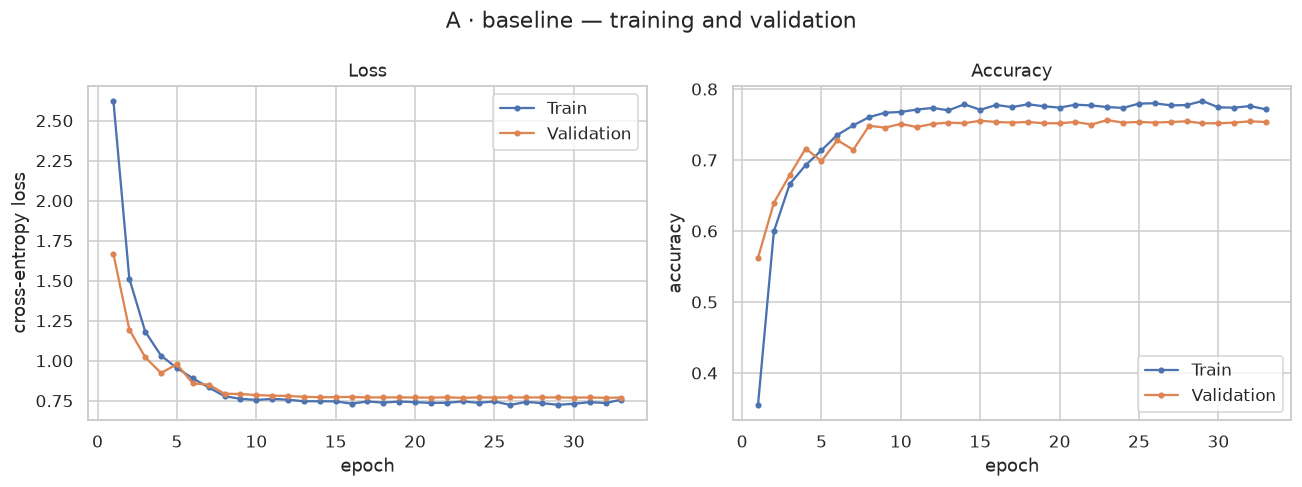

,epoch,train_loss,train_acc,val_loss,val_acc,lr,time_sec,best_val_acc
28,29,0.724109,0.783145,0.770528,0.751779,1.000000e-07,39.776393,0.756228
29,30,0.730585,0.774151,0.769407,0.751779,1.000000e-07,41.023577,0.756228
30,31,0.740975,0.773706,0.769986,0.752669,1.000000e-07,40.834602,0.756228
31,32,0.735227,0.776038,0.768314,0.754448,1.000000e-07,40.669863,0.756228
32,33,0.756791,0.771264,0.769685,0.753559,1.000000e-07,40.701715,0.756228


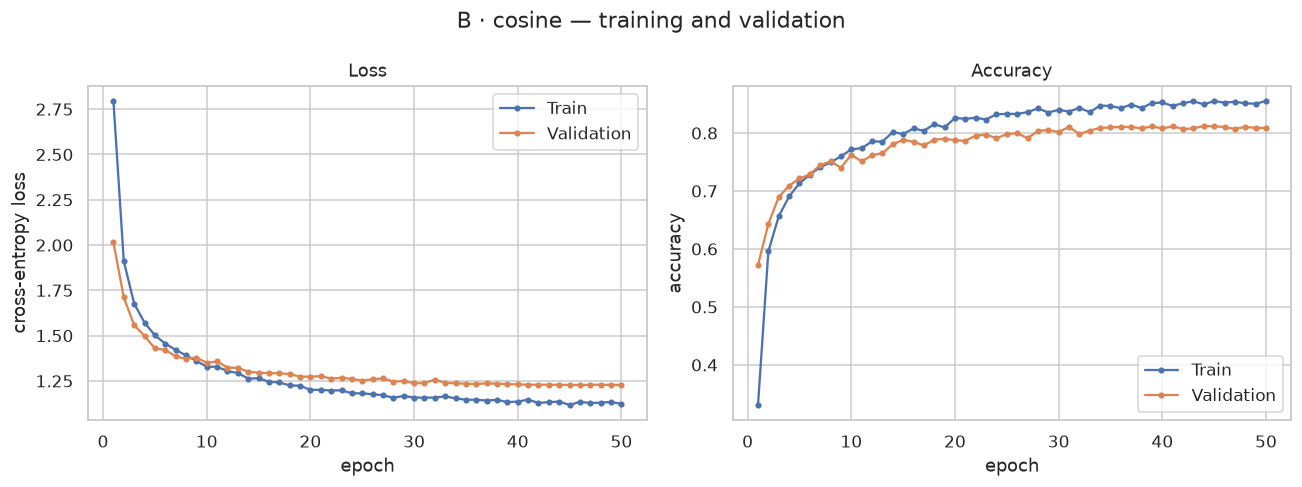

,epoch,train_loss,train_acc,val_loss,val_acc,lr,time_sec,best_val_acc
45,46,1.134714,0.852321,1.227085,0.810498,1.570842e-05,43.233783,0.812278
46,47,1.127403,0.853764,1.228527,0.806940,8.856375e-06,41.614640,0.812278
47,48,1.129961,0.851210,1.228479,0.810498,3.942649e-06,42.028413,0.812278
48,49,1.133663,0.850433,1.227746,0.808719,9.866358e-07,40.860715,0.812278
49,50,1.122620,0.855208,1.227661,0.808719,0.000000e+00,41.379935,0.812278


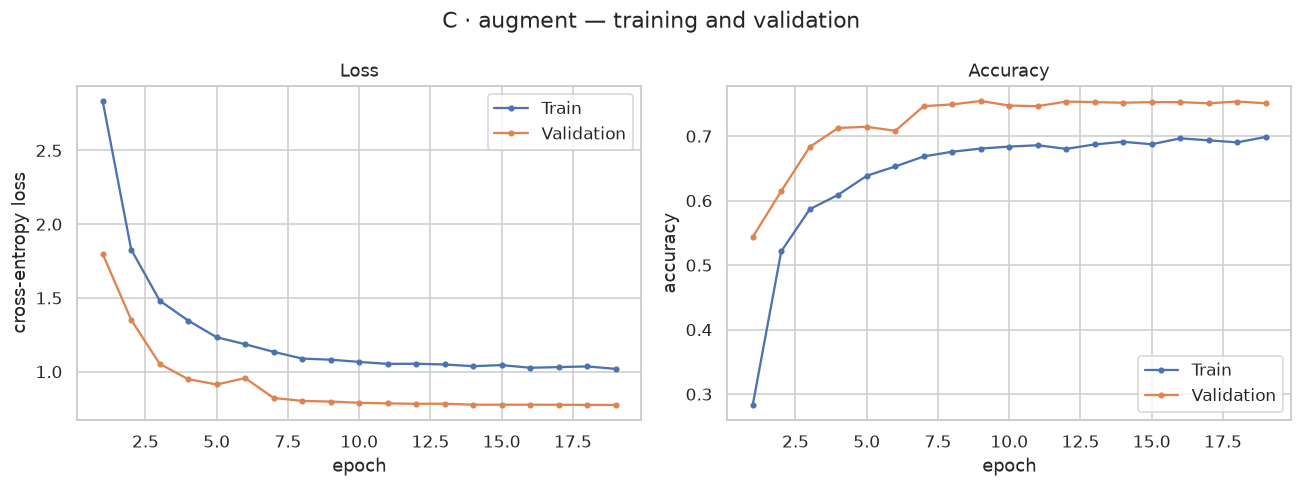

,epoch,train_loss,train_acc,val_loss,val_acc,lr,time_sec,best_val_acc
14,15,1.044601,0.687320,0.775892,0.752669,0.00001,75.633977,0.754448
15,16,1.026286,0.696536,0.776154,0.752669,0.00001,76.068598,0.754448
16,17,1.030953,0.693427,0.775254,0.750890,0.00001,68.991171,0.754448
17,18,1.035397,0.690318,0.774844,0.753559,0.00001,68.673281,0.754448
18,19,1.018764,0.698645,0.774171,0.750890,0.00001,68.775897,0.754448


In [10]:
def plot_training_curves(history, title: str, output_path: Path):
    frame = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    axes[0].plot(frame["epoch"], frame["train_loss"], marker="o", ms=3, label="Train")
    axes[0].plot(frame["epoch"], frame["val_loss"], marker="o", ms=3, label="Validation")
    axes[0].set_xlabel("epoch")
    axes[0].set_ylabel("cross-entropy loss")
    axes[0].set_title("Loss")
    axes[0].legend()

    axes[1].plot(frame["epoch"], frame["train_acc"], marker="o", ms=3, label="Train")
    axes[1].plot(frame["epoch"], frame["val_acc"], marker="o", ms=3, label="Validation")
    axes[1].set_xlabel("epoch")
    axes[1].set_ylabel("accuracy")
    axes[1].set_title("Accuracy")
    axes[1].legend()

    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(output_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)


for name, run in runs.items():
    plot_training_curves(
        run["history"],
        f"{run['label']} — training and validation",
        FIGURE_DIR / f"{name}_curves.png",
    )
    display(pd.DataFrame(run["history"]).tail())

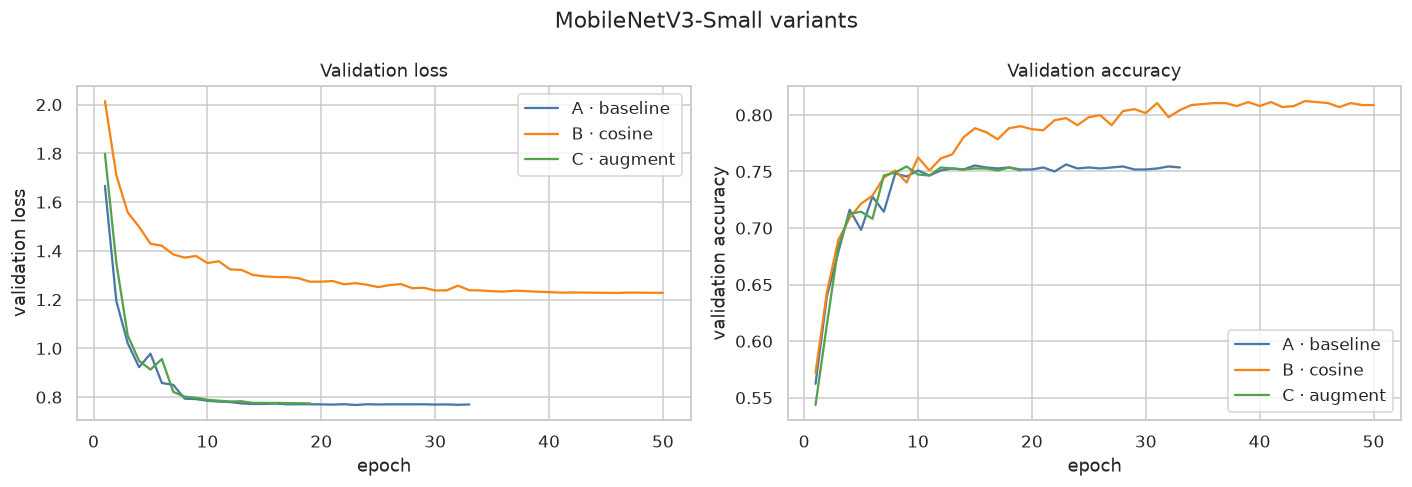

In [11]:
variant_colors = {"mobilenetv3small": "#4C78A8",
                  "mobilenetv3small_cosine": "#F58518",
                  "mobilenetv3small_aug": "#54A24B"}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, run in runs.items():
    frame = pd.DataFrame(run["history"])
    axes[0].plot(frame["epoch"], frame["val_loss"],
                 label=run["label"], color=variant_colors[name])
    axes[1].plot(frame["epoch"], frame["val_acc"],
                 label=run["label"], color=variant_colors[name])

axes[0].set_xlabel("epoch")
axes[0].set_ylabel("validation loss")
axes[0].set_title("Validation loss")
axes[0].legend()
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("validation accuracy")
axes[1].set_title("Validation accuracy")
axes[1].legend()

fig.suptitle("MobileNetV3-Small variants")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "mobilenetv3small_variants_curves.png", bbox_inches="tight")
plt.show()
plt.close(fig)

## 8. Evaluasi test

In [12]:
def jsonable(obj):
    if isinstance(obj, dict):
        return {str(k): jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [jsonable(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    if isinstance(obj, Path):
        return str(obj)
    return obj


def aggregate_major_probs(probs: np.ndarray, class_names):
    major_probs = np.zeros((probs.shape[0], len(MAJOR_NAMES)), dtype=np.float64)
    for class_idx, class_name in enumerate(class_names):
        major_probs[:, MAJOR_TO_IDX[CLASS_TO_MAJOR[class_name]]] += probs[:, class_idx]
    return major_probs


@torch.no_grad()
def predict_loader(model, loader, criterion, device):
    model.eval()
    all_probs, all_labels = [], []
    total_loss = 0.0
    total_samples = 0

    for images, labels in tqdm(loader, desc="Evaluating", leave=False):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        outputs = model(images)
        loss = criterion(outputs, labels)

        probs = torch.softmax(outputs, dim=1)
        all_probs.append(probs.cpu().numpy())
        all_labels.append(labels.cpu().numpy())
        total_loss += loss.item() * labels.size(0)
        total_samples += labels.size(0)

    if total_samples == 0:
        raise RuntimeError("Empty evaluation loader.")
    probs = np.concatenate(all_probs, axis=0)
    labels = np.concatenate(all_labels, axis=0)
    return probs, labels, total_loss / total_samples


def plot_confusion_matrix(cm, labels, title, output_path, normalize=True):
    cm = np.asarray(cm, dtype=np.float64)
    if normalize:
        row_sums = cm.sum(axis=1, keepdims=True)
        plot_cm = np.divide(cm, row_sums, out=np.zeros_like(cm), where=row_sums != 0)
        fmt = ".2f"
    else:
        plot_cm = cm
        fmt = "d"

    annot = len(labels) <= 12
    fig, ax = plt.subplots(figsize=(max(7, len(labels) * 0.48), max(6, len(labels) * 0.42)))
    sns.heatmap(
        plot_cm,
        annot=annot,
        fmt=fmt,
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels,
        ax=ax,
        cbar=True,
        linewidths=0.2 if annot else 0,
        annot_kws={"fontsize": 9} if annot else None,
    )
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=90, labelsize=7)
    ax.tick_params(axis="y", rotation=0, labelsize=7)
    fig.tight_layout()
    fig.savefig(output_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def evaluate_and_save(model, loader, criterion, device, frame, model_key):
    probs, labels, loss = predict_loader(model, loader, criterion, device)
    preds = probs.argmax(axis=1)

    report_dict = classification_report(
        labels,
        preds,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )
    cm = confusion_matrix(labels, preds, labels=np.arange(NUM_CLASSES))
    per_class_acc = np.divide(
        cm.diagonal(),
        cm.sum(axis=1),
        out=np.zeros(NUM_CLASSES, dtype=np.float64),
        where=cm.sum(axis=1) != 0,
    )

    major_probs = aggregate_major_probs(probs, CLASS_NAMES)
    major_true = frame["class_name"].map(lambda c: MAJOR_TO_IDX[CLASS_TO_MAJOR[c]]).to_numpy()
    major_pred = np.array([
        MAJOR_TO_IDX[CLASS_TO_MAJOR[CLASS_NAMES[int(index)]]] for index in preds
    ])
    major_prob_pred = major_probs.argmax(axis=1)
    major_report = classification_report(
        major_true,
        major_pred,
        labels=np.arange(len(MAJOR_NAMES)),
        target_names=MAJOR_NAMES,
        output_dict=True,
        zero_division=0,
    )
    major_cm = confusion_matrix(major_true, major_pred, labels=np.arange(len(MAJOR_NAMES)))

    prediction_frame = frame[["rel_path", "class_name", "source_group"]].copy()
    prediction_frame["true_label"] = labels
    prediction_frame["pred_label"] = preds
    prediction_frame["pred_class"] = [CLASS_NAMES[i] for i in preds]
    prediction_frame["confidence"] = probs.max(axis=1)
    prediction_frame["correct"] = (labels == preds).astype(int)
    for class_idx, class_name in enumerate(CLASS_NAMES):
        prediction_frame[f"prob_{class_name}"] = probs[:, class_idx]
    prediction_frame.to_csv(RESULT_DIR / f"{model_key}_predictions.csv", index=False)

    metrics = {
        "model": model_key,
        "split": "test",
        "num_test": int(len(labels)),
        "accuracy": float(accuracy_score(labels, preds)),
        "loss": float(loss),
        "top3_accuracy": float(
            top_k_accuracy_score(
                labels,
                probs,
                k=min(3, NUM_CLASSES),
                labels=np.arange(NUM_CLASSES),
            )
        ),
        "macro_f1": float(report_dict["macro avg"]["f1-score"]),
        "weighted_f1": float(report_dict["weighted avg"]["f1-score"]),
        "per_class_accuracy": {
            name: float(per_class_acc[i]) for i, name in enumerate(CLASS_NAMES)
        },
        "group_accuracy": {
            str(group): float(sub["correct"].mean())
            for group, sub in prediction_frame.groupby("source_group")
        },
        "classification_report": report_dict,
        "confusion_matrix": cm.tolist(),
        "major_accuracy": float(accuracy_score(major_true, major_pred)),
        "major_prob_accuracy": float(accuracy_score(major_true, major_prob_pred)),
        "major_report": major_report,
        "major_confusion_matrix": major_cm.tolist(),
        "major_class_names": MAJOR_NAMES,
        "class_names": CLASS_NAMES,
    }
    with open(RESULT_DIR / f"{model_key}_metrics.json", "w") as handle:
        json.dump(jsonable(metrics), handle, indent=2)

    pd.DataFrame(report_dict).T.to_csv(RESULT_DIR / f"{model_key}_classification_report.csv")
    pd.DataFrame(major_report).T.to_csv(RESULT_DIR / f"{model_key}_major_report.csv")
    pd.DataFrame(
        per_class_acc, index=CLASS_NAMES, columns=["accuracy"]
    ).to_csv(RESULT_DIR / f"{model_key}_per_class_accuracy.csv")

    print(f"\n{model_key} — test results")
    print(f"  loss              : {metrics['loss']:.4f}")
    print(f"  30-class accuracy : {metrics['accuracy'] * 100:.2f}%")
    print(f"  macro F1 (30)     : {metrics['macro_f1']:.4f}")
    print(f"  top-3 accuracy    : {metrics['top3_accuracy'] * 100:.2f}%")
    print(f"  3-class accuracy  : {metrics['major_accuracy'] * 100:.2f}% (top-1 prefix)")
    print(f"  3-class prob agg  : {metrics['major_prob_accuracy'] * 100:.2f}%")
    print("  accuracy by source group:")
    for group, value in metrics["group_accuracy"].items():
        print(f"    {group:10s}: {value * 100:.2f}%")

    return metrics, probs, labels, preds, major_true, major_pred

In [13]:
eval_criterion = nn.CrossEntropyLoss()
evaluations = {}

for name, run in runs.items():
    eval_model = build_mobilenet_v3_small(NUM_CLASSES, pretrained=False).to(DEVICE)
    ckpt = load_checkpoint(run["checkpoint"], DEVICE)
    eval_model.load_state_dict(ckpt["state_dict"])
    eval_model.eval()
    print(f"\n{name}: checkpoint epoch {ckpt['epoch']} (val acc {ckpt['val_acc']:.4f})")

    (
        metrics,
        test_probs,
        test_labels,
        test_preds,
        major_true,
        major_pred,
    ) = evaluate_and_save(
        eval_model, test_loader, eval_criterion, DEVICE, test_df, model_key=name
    )

    evaluations[name] = {
        "metrics": metrics,
        "model": eval_model,
        "probabilities": test_probs,
        "labels": test_labels,
        "predictions": test_preds,
    }
    display(pd.DataFrame(metrics["major_report"]).T.round(3))


mobilenetv3small: checkpoint epoch 23 (val acc 0.7562)


Evaluating:   0%|                                                                                                                                                    | 0/9 [00:00<?, ?it/s]

Evaluating:  11%|███████████████▌                                                                                                                            | 1/9 [00:02<00:17,  2.25s/it]

Evaluating:  22%|███████████████████████████████                                                                                                             | 2/9 [00:04<00:17,  2.43s/it]

Evaluating:  33%|██████████████████████████████████████████████▋                                                                                             | 3/9 [00:06<00:13,  2.26s/it]

Evaluating:  44%|██████████████████████████████████████████████████████████████▏                                                                             | 4/9 [00:09<00:11,  2.24s/it]

... (29 outputs left out)

Evaluating:  89%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▍               | 8/9 [00:02<00:00,  2.79it/s]

Evaluating: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 9/9 [00:02<00:00,  3.19it/s]


mobilenetv3small_aug — test results
  loss              : 0.7092
  30-class accuracy : 77.85%
  macro F1 (30)     : 0.7725
  top-3 accuracy    : 92.06%
  3-class accuracy  : 91.09% (top-1 prefix)
  3-class prob agg  : 92.06%
  accuracy by source group:
    default   : 82.01%
    real_world: 70.96%


,precision,recall,f1-score,support
Kitchen waste,0.872,0.884,0.878,147.000
Recyclable waste,0.949,0.927,0.938,767.000
Other waste,0.813,0.872,0.841,219.000
accuracy,0.911,0.911,0.911,0.911
macro avg,0.878,0.894,0.886,1133.000
weighted avg,0.913,0.911,0.912,1133.000


In [14]:
insight_rows = []
for name, evaluation in evaluations.items():
    metric = evaluation["metrics"]
    insight_rows.append({
        "Varian": runs[name]["label"],
        "Prefix": name,
        "Test accuracy (%)": metric["accuracy"] * 100,
        "Cross-entropy loss": metric["loss"],
        "Top-3 accuracy (%)": metric["top3_accuracy"] * 100,
        "3-class accuracy (%)": metric["major_accuracy"] * 100,
        "3-class prob accuracy (%)": metric["major_prob_accuracy"] * 100,
        "Macro F1 (30 kelas)": metric["macro_f1"],
        "Macro F1 (3 major class)": metric["major_report"]["macro avg"]["f1-score"],
        "Parameters (M)": count_parameters(evaluation["model"]) / 1e6,
    })

variant_table = pd.DataFrame(insight_rows).set_index("Varian")
display(variant_table.round(3))
variant_table.to_csv(RESULT_DIR / "mobilenetv3small_variants_metrics.csv")

,Prefix,Test accuracy (%),Cross-entropy loss,Top-3 accuracy (%),3-class accuracy (%),3-class prob accuracy (%),Macro F1 (30 kelas),Macro F1 (3 major class),Parameters (M)
Varian,,,,,,,,,
A · baseline,mobilenetv3small,80.759,0.654,92.851,92.939,93.204,0.804,0.907,1.549
B · cosine,mobilenetv3small_cosine,83.407,0.618,95.322,94.969,95.146,0.826,0.933,1.549
C · augment,mobilenetv3small_aug,77.846,0.709,92.056,91.086,92.056,0.772,0.886,1.549


## 9. Confusion matrix

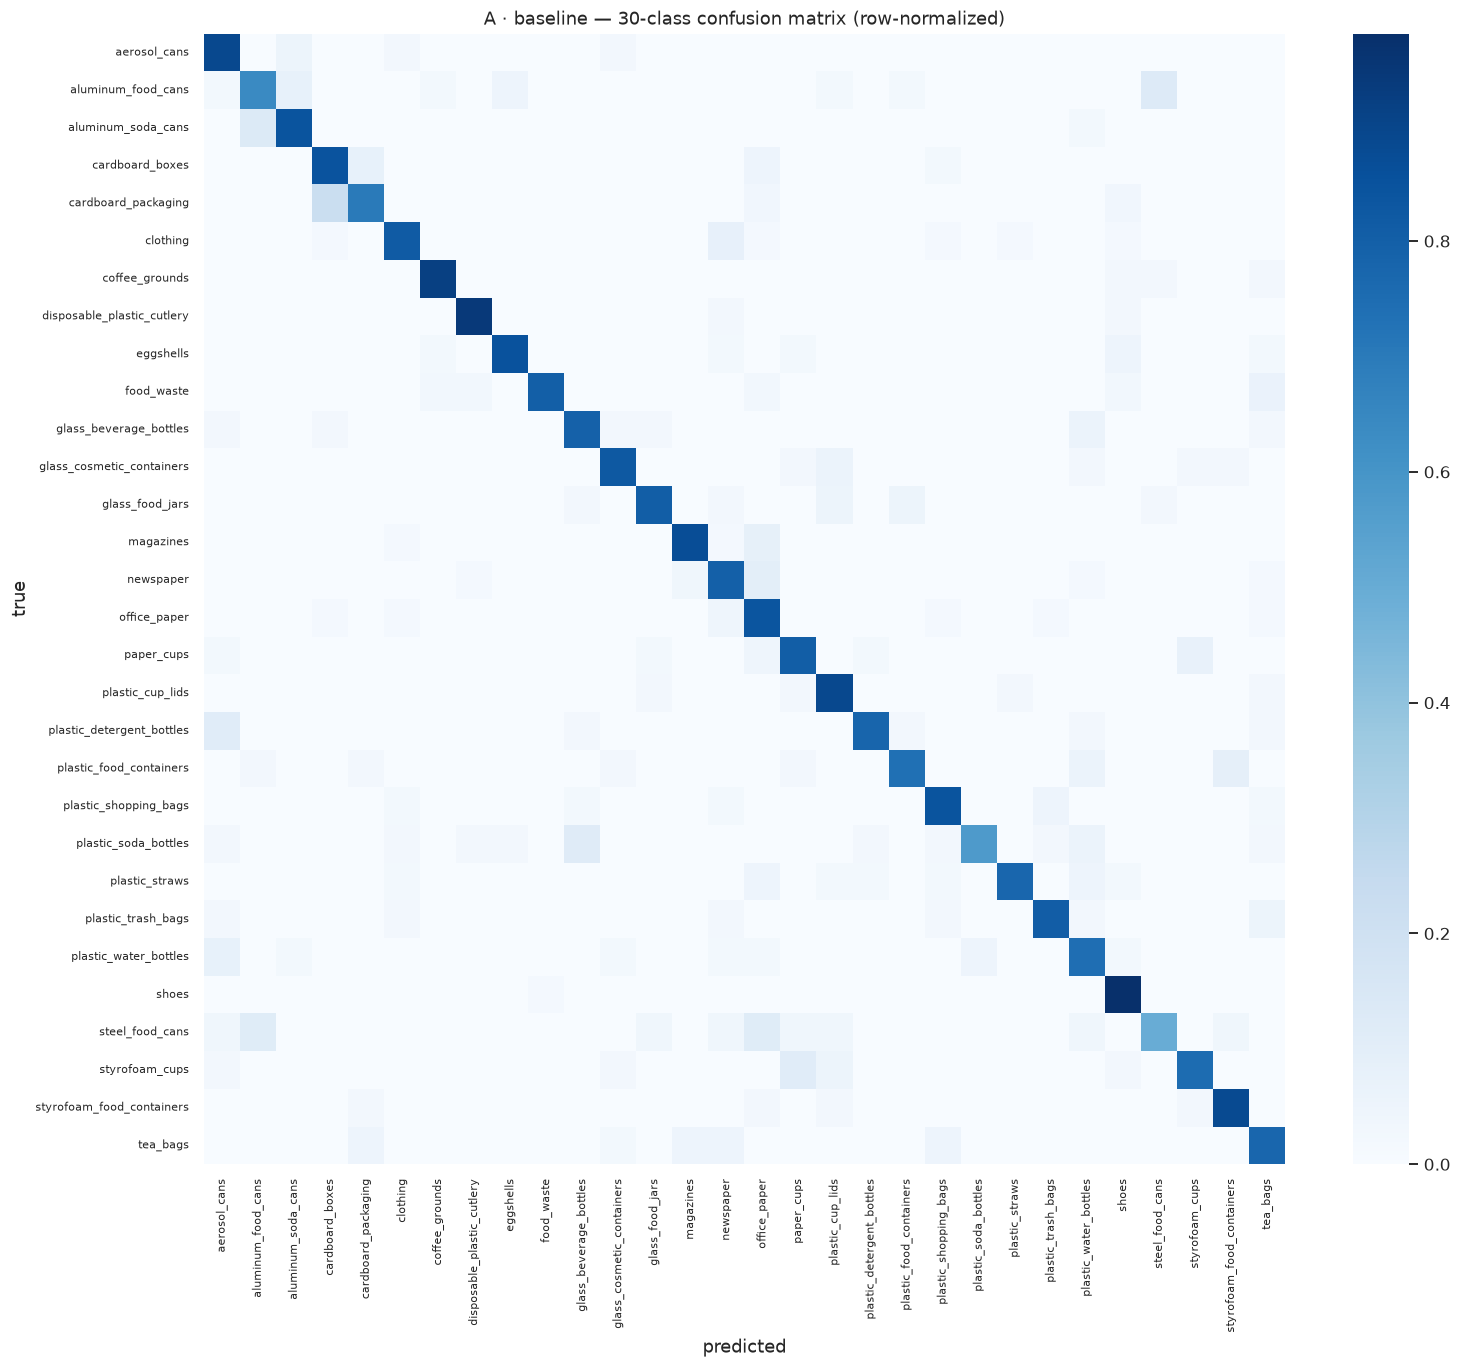

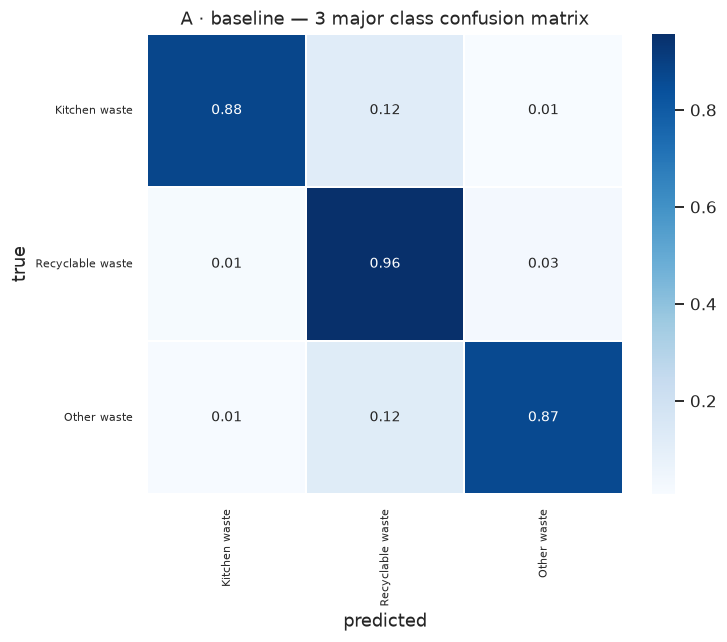

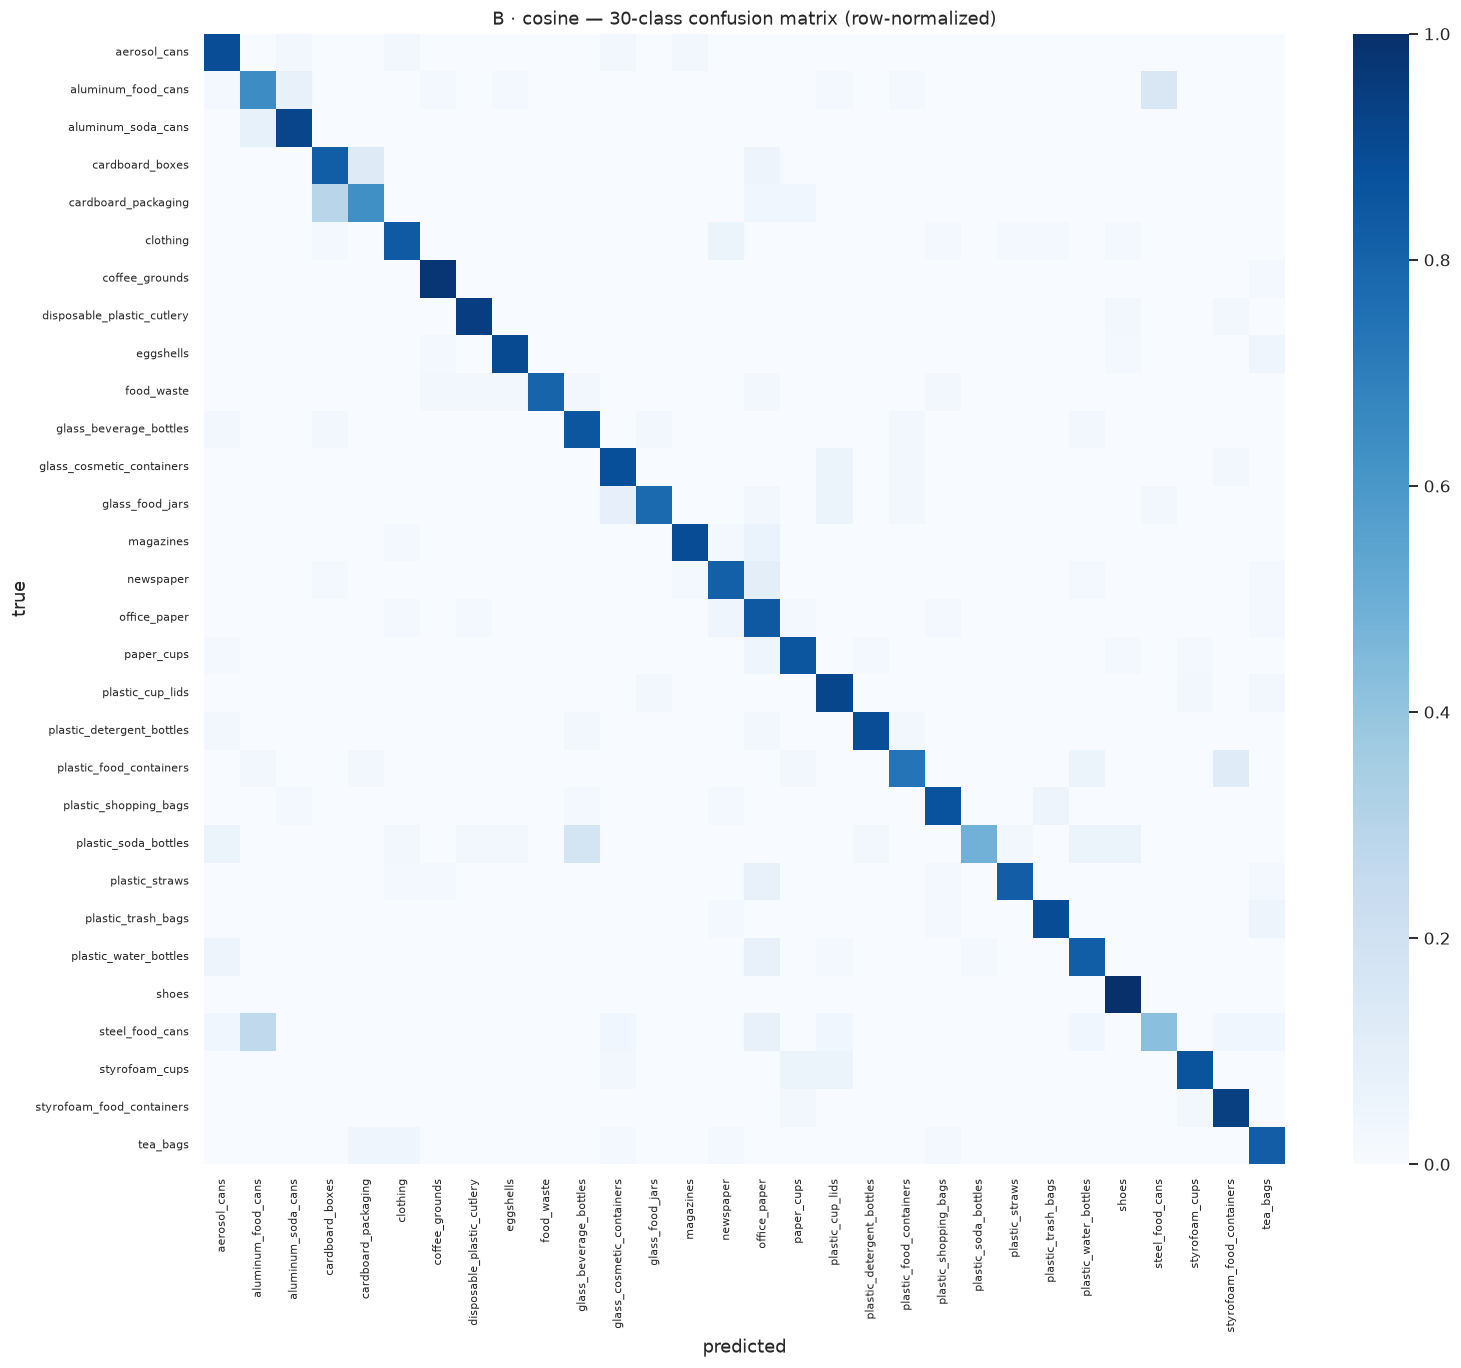

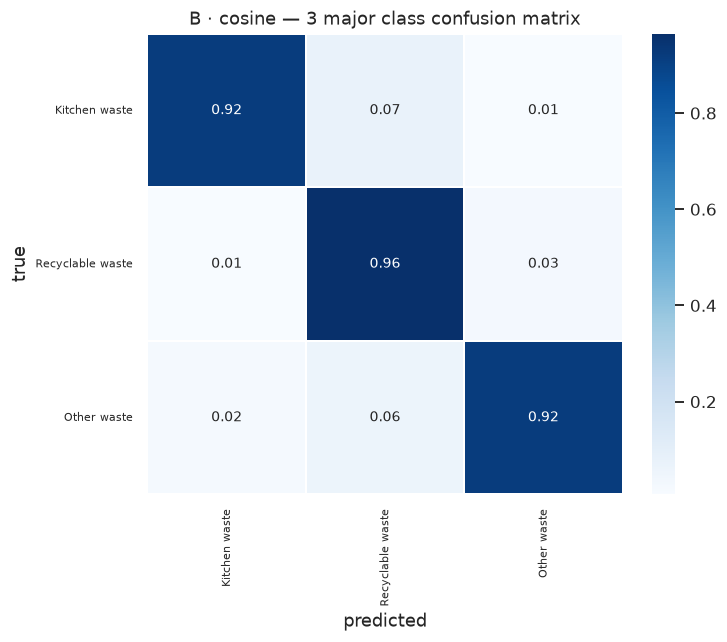

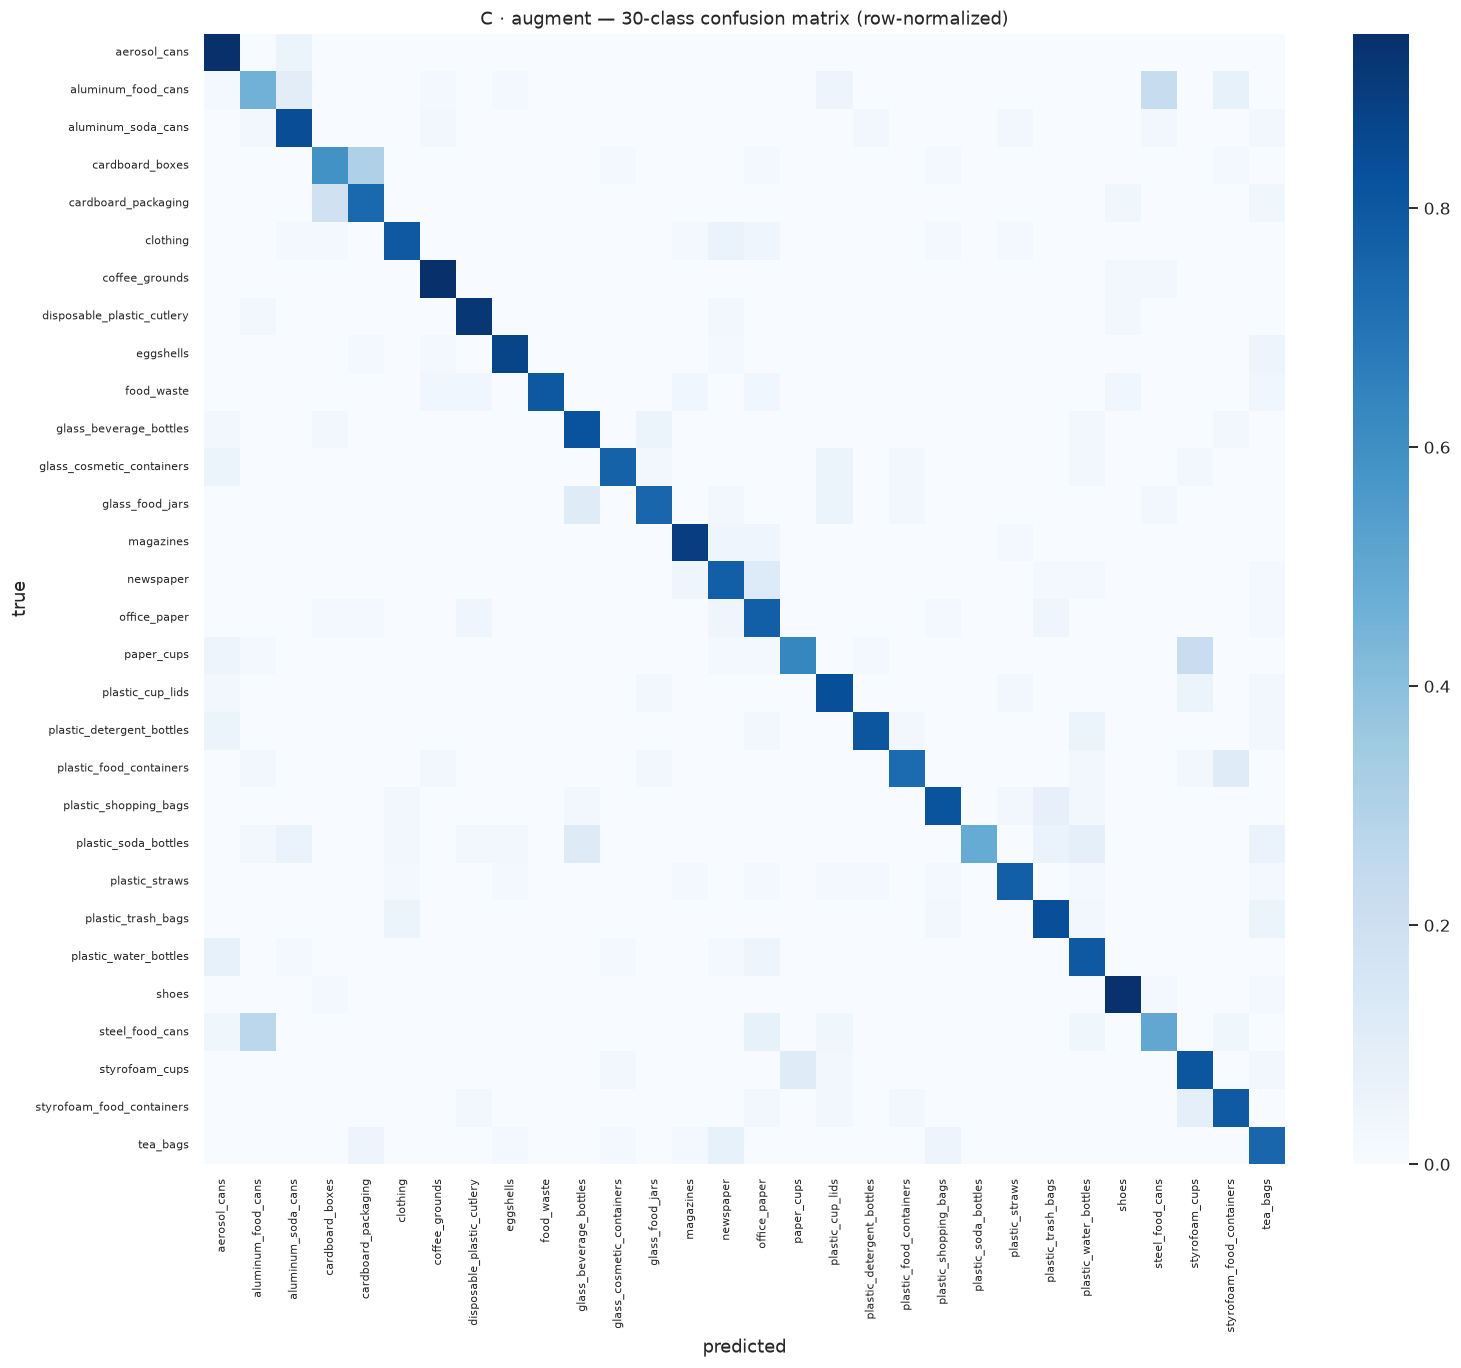

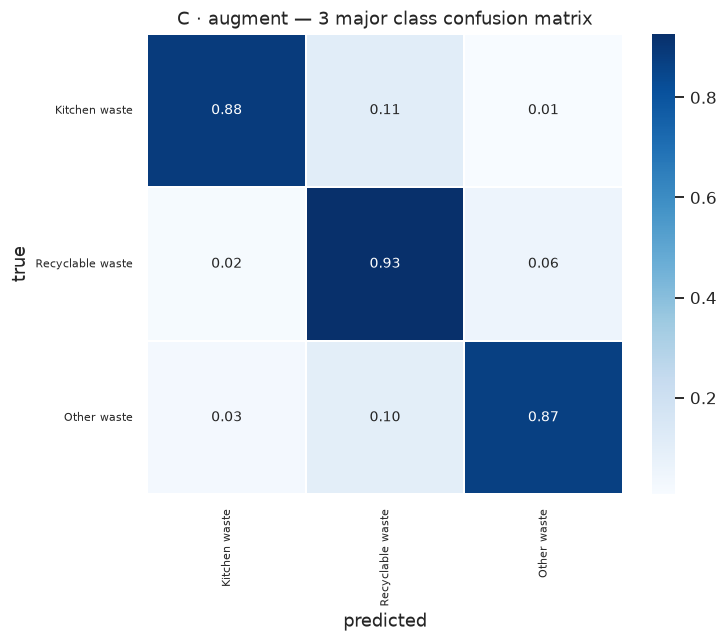

In [15]:
for name, evaluation in evaluations.items():
    metric = evaluation["metrics"]
    label = runs[name]["label"]

    plot_confusion_matrix(
        np.array(metric["confusion_matrix"]),
        CLASS_NAMES,
        f"{label} — 30-class confusion matrix (row-normalized)",
        FIGURE_DIR / f"{name}_confusion_30.png",
        normalize=True,
    )
    plot_confusion_matrix(
        np.array(metric["major_confusion_matrix"]),
        MAJOR_NAMES,
        f"{label} — 3 major class confusion matrix",
        FIGURE_DIR / f"{name}_confusion_major.png",
        normalize=True,
    )

## 10. Analisis error

Semua varian diekspor ke CSV. Gambar contoh hanya dibuat untuk varian dengan test accuracy tertinggi.

Best variant: B · cosine mobilenetv3small_cosine
A · baseline: 218 salah dari 1,133 gambar test


,true_class,pred_class,count
0,cardboard_packaging,cardboard_boxes,6
1,aluminum_soda_cans,aluminum_food_cans,5
2,aluminum_food_cans,steel_food_cans,5
3,newspaper,office_paper,5
4,plastic_soda_bottles,glass_beverage_bottles,4


B · cosine: 188 salah dari 1,133 gambar test


,true_class,pred_class,count
0,cardboard_packaging,cardboard_boxes,8
1,steel_food_cans,aluminum_food_cans,7
2,plastic_soda_bottles,glass_beverage_bottles,6
3,aluminum_food_cans,steel_food_cans,6
4,cardboard_boxes,cardboard_packaging,5


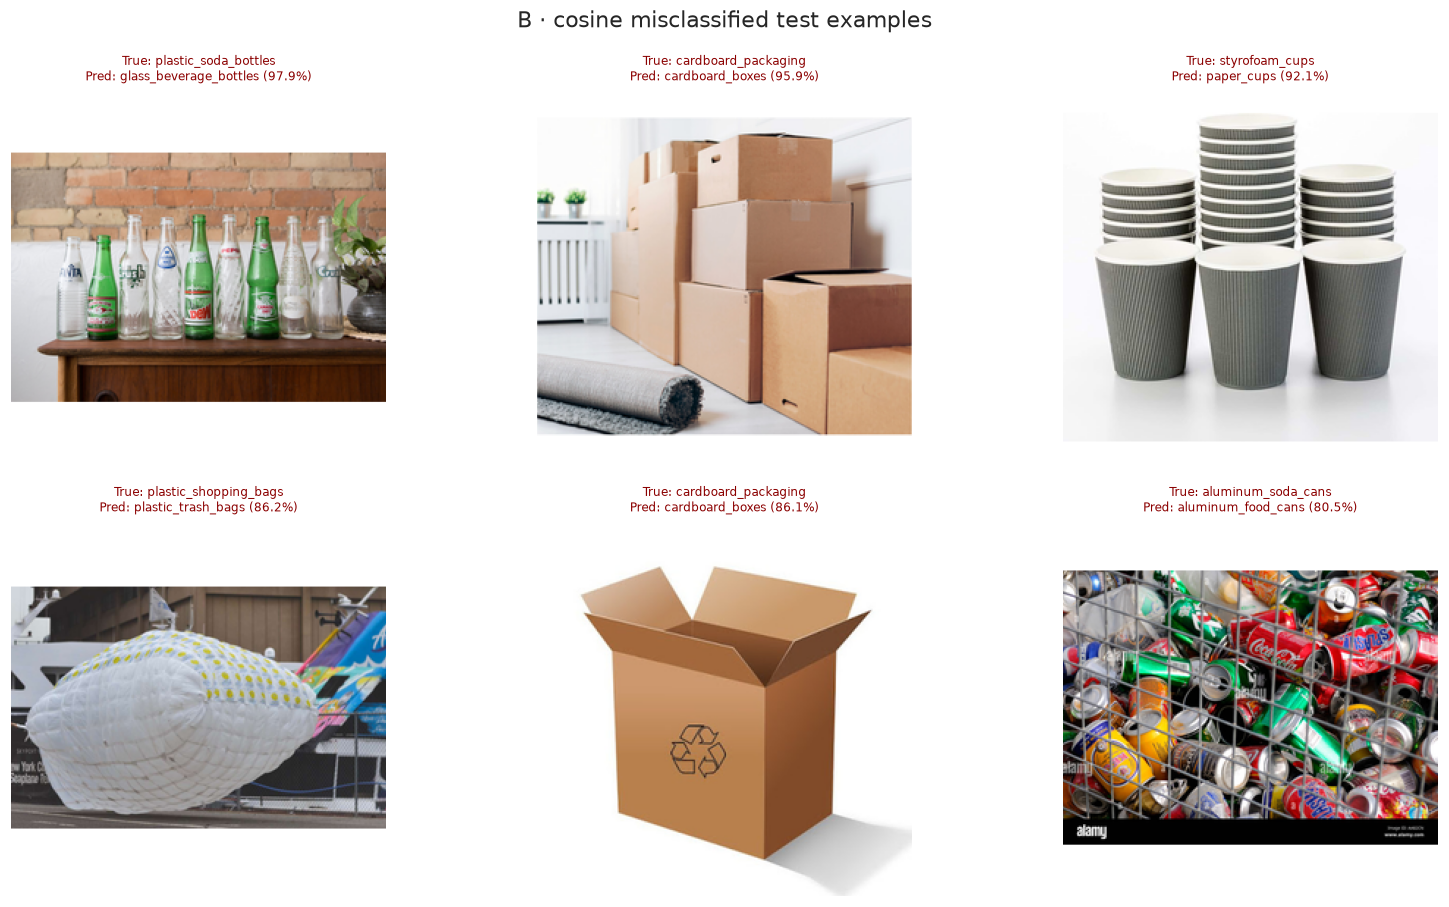

C · augment: 251 salah dari 1,133 gambar test


,true_class,pred_class,count
0,cardboard_boxes,cardboard_packaging,12
1,aluminum_food_cans,steel_food_cans,9
2,paper_cups,styrofoam_cups,9
3,steel_food_cans,aluminum_food_cans,7
4,newspaper,office_paper,6


In [16]:
def build_prediction_frame(frame, probs, labels, preds):
    result = frame[["rel_path", "class_name", "source_group"]].copy()
    result["true_class"] = [CLASS_NAMES[int(i)] for i in labels]
    result["pred_class"] = [CLASS_NAMES[int(i)] for i in preds]
    result["confidence"] = probs.max(axis=1)
    result["correct"] = result["true_class"].eq(result["pred_class"])
    return result


def show_misclassified(predictions, model_name, output_stem, output_path, max_examples=6,
                       make_figure=True):
    errors = (
        predictions[~predictions["correct"]]
        .sort_values("confidence", ascending=False)
        .reset_index(drop=True)
    )
    print(f"{model_name}: {len(errors):,} salah dari {len(predictions):,} gambar test")
    if errors.empty:
        return errors

    errors.to_csv(RESULT_DIR / f"{output_stem}_misclassified.csv", index=False)
    display(
        errors.groupby(["true_class", "pred_class"])
        .size()
        .sort_values(ascending=False)
        .head(5)
        .rename("count")
        .reset_index()
    )

    if not make_figure:
        return errors

    examples = errors.head(max_examples)
    ncols = min(3, len(examples))
    nrows = math.ceil(len(examples) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.2 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (_, row) in zip(axes, examples.iterrows()):
        with Image.open(DATA_ROOT / row["rel_path"]) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(
            f"True: {row['true_class']}\nPred: {row['pred_class']} ({row['confidence'] * 100:.1f}%)",
            fontsize=8,
            color="darkred",
        )
        ax.axis("off")
    for ax in axes[len(examples):]:
        ax.axis("off")
    fig.suptitle(f"{model_name} misclassified test examples")
    fig.tight_layout()
    fig.savefig(output_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return errors


best_name = max(evaluations, key=lambda k: evaluations[k]["metrics"]["accuracy"])
print("Best variant:", runs[best_name]["label"], best_name)

all_errors = {}
for name, evaluation in evaluations.items():
    predictions = build_prediction_frame(
        test_df, evaluation["probabilities"], evaluation["labels"], evaluation["predictions"]
    )
    all_errors[name] = show_misclassified(
        predictions,
        runs[name]["label"],
        name,
        FIGURE_DIR / f"{name}_misclassified_examples.png",
        make_figure=(name == best_name),
    )

## 11. Perbandingan dengan baseline

MobileNetV2 dan CNN dibaca dari `outputs/results/`. Tiga varian MobileNetV3-Small dari run ini.

In [17]:
comparison = variant_table.drop(columns=["Prefix"]).copy()
comparison["Parameters (M)"] = comparison["Parameters (M)"].round(3)

baseline_path = RESULT_DIR / "model_comparison.csv"
insight_path = RESULT_DIR / "model_insights.csv"
if baseline_path.exists():
    baseline = pd.read_csv(baseline_path).set_index("Model")
    if insight_path.exists():
        extra = pd.read_csv(insight_path).set_index("Model")
        extra = extra.rename(columns={"Macro F1": "Macro F1 (30 kelas)"})
        baseline = baseline.join(extra, how="left")
    baseline = baseline.reindex(columns=comparison.columns)
    comparison = pd.concat([comparison, baseline])

comparison.to_csv(RESULT_DIR / "mobilenetv3small_variants_comparison.csv")
display(comparison.round(3))

,Test accuracy (%),Cross-entropy loss,Top-3 accuracy (%),3-class accuracy (%),3-class prob accuracy (%),Macro F1 (30 kelas),Macro F1 (3 major class),Parameters (M)
A · baseline,80.759,0.654,92.851,92.939,93.204,0.804,0.907,1.549
B · cosine,83.407,0.618,95.322,94.969,95.146,0.826,0.933,1.549
C · augment,77.846,0.709,92.056,91.086,92.056,0.772,0.886,1.549
MobileNetV2,85.172,0.465,96.117,96.205,96.558,0.844,NaN,2.262
CNN,40.071,4.341,56.664,72.021,73.786,0.392,NaN,23.911


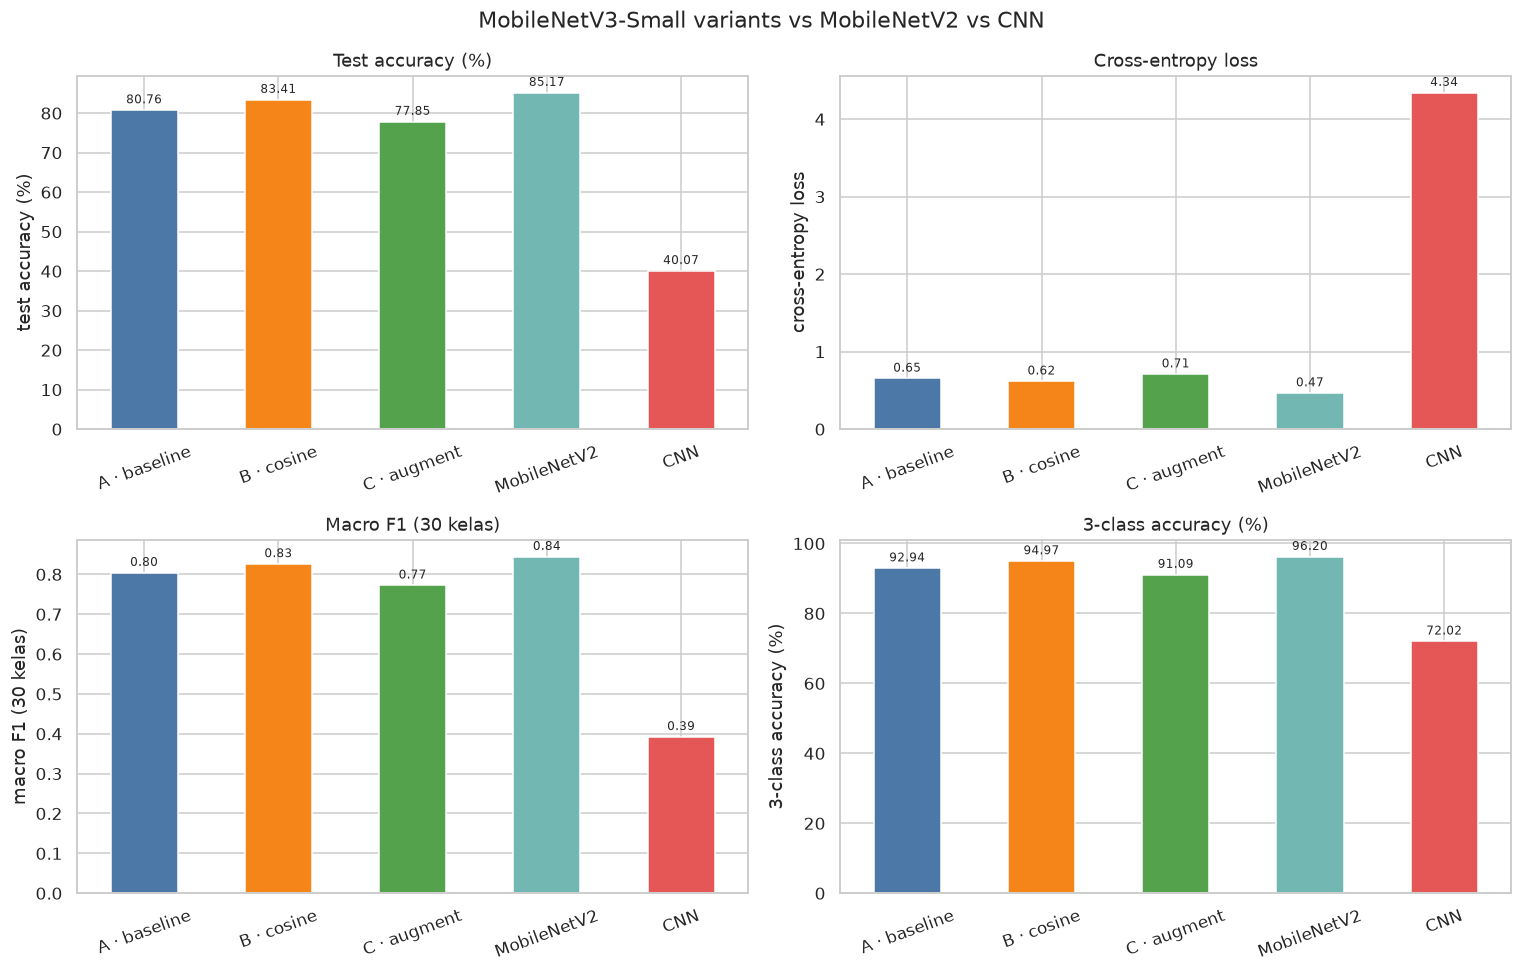

In [18]:
plot_metrics = [
    ("Test accuracy (%)", "test accuracy (%)"),
    ("Cross-entropy loss", "cross-entropy loss"),
    ("Macro F1 (30 kelas)", "macro F1 (30 kelas)"),
    ("3-class accuracy (%)", "3-class accuracy (%)"),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.ravel()
bar_colors = ["#4C78A8", "#F58518", "#54A24B", "#72B7B2", "#E45756"][:len(comparison)]

for ax, (column, ylabel) in zip(axes, plot_metrics):
    values = comparison[column].astype(float)
    values.plot(kind="bar", ax=ax, color=bar_colors)
    ax.set_ylabel(ylabel)
    ax.set_title(column)
    ax.tick_params(axis="x", rotation=20)
    offset = values.max() * 0.02
    for i, value in enumerate(values):
        ax.text(i, value + offset, f"{value:.2f}", ha="center", fontsize=8)

fig.suptitle("MobileNetV3-Small variants vs MobileNetV2 vs CNN")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "mobilenetv3small_variants_comparison.png", bbox_inches="tight")
plt.show()
plt.close(fig)

## 12. Simpan ringkasan

In [19]:
variant_records = {}
for name, run in runs.items():
    metric = evaluations[name]["metrics"]
    variant_records[name] = {
        "label": run["label"],
        "config": {
            "scheduler": run["spec"]["scheduler"],
            "label_smoothing": run["spec"]["label_smoothing"],
            "weight_decay": run["spec"]["weight_decay"],
            "class_weight": run["spec"]["class_weight"],
            "augmentation": "trivialaugment+colorjitter+randomerasing"
            if run["spec"]["class_weight"] else "randomresizedcrop+flip",
        },
        "best_epoch": int(run["best_epoch"]),
        "best_val_acc": float(run["best_val_acc"]),
        "epochs_run": len(run["history"]),
        "early_stopped": len(run["history"]) < NUM_EPOCHS,
        "parameters": count_parameters(evaluations[name]["model"]),
        "metrics": {
            "accuracy": metric["accuracy"],
            "loss": metric["loss"],
            "top3_accuracy": metric["top3_accuracy"],
            "major_accuracy": metric["major_accuracy"],
            "major_prob_accuracy": metric["major_prob_accuracy"],
            "macro_f1": metric["macro_f1"],
            "weighted_f1": metric["weighted_f1"],
            "macro_f1_major": metric["major_report"]["macro avg"]["f1-score"],
            "group_accuracy": metric["group_accuracy"],
        },
        "artifacts": {
            "checkpoint": str(run["checkpoint"]),
            "full_model": str(run["full_model"]),
            "history": str(run["history_csv"]),
            "metrics": str(RESULT_DIR / f"{name}_metrics.json"),
        },
    }

summary = {
    "paper": {
        "title": "Application of MobileNetV2 to waste classification",
        "authors": "Yong, Ma, Sun, Du",
        "journal": "PLOS ONE 18(3): e0282336",
        "doi": "10.1371/journal.pone.0282336",
    },
    "arch": "mobilenet_v3_small",
    "pretrained": PRETRAINED,
    "dataset": {
        "root": str(DATA_ROOT),
        "split_manifest": str(SPLIT_MANIFEST),
        "num_classes": NUM_CLASSES,
        "num_images": int(len(df)),
        "split_sizes": {
            split_name: int((df["split"] == split_name).sum())
            for split_name in ("train", "val", "test")
        },
        "major_names": MAJOR_NAMES,
        "class_to_major": CLASS_TO_MAJOR,
    },
    "training": {
        "img_size": IMG_SIZE,
        "batch_size": BATCH_SIZE,
        "num_epochs": NUM_EPOCHS,
        "learning_rate": LEARNING_RATE,
        "momentum": MOMENTUM,
        "step_size": STEP_SIZE,
        "gamma": GAMMA,
        "test_batch_size": TEST_BATCH_SIZE,
        "early_stopping_patience": EARLY_STOP_PATIENCE,
        "early_stop_min_epochs": EARLY_STOP_MIN_EPOCHS,
        "seed": SEED,
        "device": str(DEVICE),
        "quick_test": QUICK_TEST,
    },
    "variants": variant_records,
    "best_variant": best_name,
    "versions": {
        "python": sys.version.split()[0],
        "torch": torch.__version__,
        "torchvision": __import__("torchvision").__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
    },
}
with open(RESULT_DIR / "mobilenetv3small_variants_summary.json", "w") as handle:
    json.dump(jsonable(summary), handle, indent=2)
print("Wrote", RESULT_DIR / "mobilenetv3small_variants_summary.json")

print("\nOutput files:")
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file() and path.stat().st_mtime >= time.time() - 3600:
        print(f"  {path.relative_to(OUTPUT_DIR)}")

Wrote /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16/outputs/results/mobilenetv3small_variants_summary.json

Output files:
  figures/mobilenetv3small_aug_confusion_30.png
  figures/mobilenetv3small_aug_confusion_major.png
  figures/mobilenetv3small_aug_curves.png
  figures/mobilenetv3small_confusion_30.png
  figures/mobilenetv3small_confusion_major.png
  figures/mobilenetv3small_cosine_confusion_30.png
  figures/mobilenetv3small_cosine_confusion_major.png
  figures/mobilenetv3small_cosine_curves.png
  figures/mobilenetv3small_cosine_misclassified_examples.png
  figures/mobilenetv3small_curves.png
  figures/mobilenetv3small_variants_comparison.png
  figures/mobilenetv3small_variants_curves.png
  models/mobilenetv3small_aug_trash30_best.pt
  models/mobilenetv3small_aug_trash30_full.pt
  models/mobilenetv3small_cosine_trash30_best.pt
  models/mobilenetv3small_cosine_trash30_full.pt
  models/mobilenetv3small_trash30_full.pt
  results/mobilenetv3small_aug_classification_report.csv
 

## Catatan

- Tiga varian MobileNetV3-Small memakai arsitektur, split, seed, transform evaluasi, dan early
  stopping yang sama; hanya resep training yang berbeda.
- Semua varian diekspor: checkpoint, full model, history CSV, metrics JSON, classification report,
  major report, per-class accuracy, predictions, dan misclassified CSV.
- File MobileNetV2 dan CNN tidak ditimpa; perbandingan membacanya dari `outputs/results/`.